# Tarea 03 – Autoencoders (VAE vs. U-Net) sobre MVTec AD
**Curso de Inteligencia Artificial · Escuela de Ingeniería en Computación · TEC**

Comparamos un VAE y un autoencoder U-Net con skip connections reconstruyendo imágenes de 4 clases de MVTec AD
(`cable`, `capsule`, `screw`, `transistor`, 128×128×3). Cada modelo se entrena 4 veces cambiando solo la pérdida
(L1, L2, SSIM, SSIM+L1): 8 runs en total, registrados en WandB con PyTorch Lightning y Hydra.

### Cómo ejecutar
1. Abrir en Colab con GPU (*Entorno de ejecución → Cambiar tipo de entorno → GPU*).
2. Guardar la API key de WandB en los secretos de Colab con el nombre `WANDB_API_KEY` (si no está, se pide con `getpass`).
3. Primera vez: `DOWNLOAD_DATA = True` (descarga MVTec AD, conserva solo las 4 clases y las redimensiona a 128×128).
   Alternativa rápida: subir `mvtec128.zip` (lo genera P1) a la carpeta del notebook.
4. Para entrenar los 8 modelos: `RUN_TRAINING = True`. Con ambas banderas en `False` el notebook corre completo sin descargar ni entrenar.
5. *Entorno de ejecución → Reiniciar y ejecutar todo*.

### Contrato entre módulos (resumen de la sección 4 del documento de acuerdos)
- `forward(x) -> (recon, z)` y `encode(x) -> z`. `x`, `recon`: `[B, 3, 128, 128]` en `[0, 1]` (sigmoid al final). `z`: `[B, z_dim]` (en el VAE, `z = mu`).
- Pérdida: `loss = criterion(recon, x)` con el módulo común; el VAE suma `beta * KL`.
- Métricas: `train/loss`, `val/loss`, `train/recon_loss`, `val/recon_loss`, `train/kl`, `val/kl` (solo VAE), `test/recon_error`.
- Métricas comunes en **todos** los runs (para comparar pérdidas distintas en la misma escala): `train|val/mae`, `train|val/mse`, `train|val/ssim`.
- Resumen de test por run: `test/auroc_{clase}` y `test/auroc_mean` (separación buenas vs. defectuosas con el error).
- Imágenes: `val/reconstructions`, `val/tsne`, `test/reconstructions_good_defective`, `test/tsne`, `test/hist_error_{clase}`; tabla `test/errors`.
- Nombre de run: `{model}_{loss}_z{z_dim}`, `group` = modelo, `tags` = `[loss, model]`.

### Checklist (definición de terminado)
- [ ] 8 runs en WandB con los nombres y métricas acordados
- [ ] Comparación train/val de las 4 pérdidas por modelo
- [ ] Reconstrucciones de validación (16) y de prueba buenas/defectuosas (16) del mejor modelo de cada arquitectura
- [ ] t-SNE del latente por época (validación) y del test
- [ ] Histogramas de error normal vs. defectuoso por subclase de defecto
- [ ] Todas las imágenes del notebook provienen de WandB
- [ ] El notebook corre de principio a fin, anotado y con análisis crítico

## 2. Setup (P1)
Dependencias con versiones fijadas. En Colab `torch`, `scikit-learn` y `matplotlib` ya vienen instalados y no se
reinstalan (forzar versiones viejas rompe otros paquetes de Colab); sus versiones se imprimen abajo para reproducibilidad.
Cualquier dependencia nueva se agrega **en esta celda** y se avisa al grupo.

In [35]:
%pip install -q "lightning==2.4.0" "hydra-core==1.3.2" "torchmetrics==1.6.0" "wandb>=0.21"


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [36]:
# ---- Banderas de control -------------------------------------------------
DOWNLOAD_DATA = False   # True la primera vez: descarga y preprocesa MVTec AD
RUN_TRAINING  = True   # True para lanzar los 8 entrenamientos (costoso)

import io
import math
import os
import re
import shutil
import tarfile
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import lightning as L
from lightning.pytorch.callbacks import Callback, ModelCheckpoint
from lightning.pytorch.loggers import WandbLogger
from torchmetrics.functional.image import structural_similarity_index_measure
from IPython.display import Image as IPImage, display
from PIL import Image
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from omegaconf import DictConfig, OmegaConf
from hydra import compose, initialize
from hydra.core.global_hydra import GlobalHydra
from hydra.utils import instantiate
import wandb

L.seed_everything(42, workers=True)   # la semilla de cada run se vuelve a fijar desde el cfg
print("torch", torch.__version__, "| lightning", L.__version__, "| wandb", wandb.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no")


Seed set to 42


torch 2.14.1 | lightning 2.4.0 | wandb 0.31.0 | scikit-learn 1.9.1 | matplotlib 3.11.2
GPU: no


In [37]:
def _clean_key(value):
    """Devuelve la clave como texto. Algunos entornos entregan el secreto envuelto en un dict."""
    if isinstance(value, dict):
        value = value.get("value") or value.get("key") or next(iter(value.values()), None)
    return value.strip() if isinstance(value, str) and value.strip() else None


def wandb_login():
    """Pide la API key sin dejarla escrita en el notebook: variable de entorno, secreto de Colab o getpass."""
    key, source = _clean_key(os.environ.get("WANDB_API_KEY")), "variable de entorno"
    if not key:
        try:
            from google.colab import userdata
            key, source = _clean_key(userdata.get("WANDB_API_KEY")), "secreto de Colab"
        except Exception:
            key = None
    if not key:
        from getpass import getpass
        key, source = _clean_key(getpass("API key de WandB: ")), "getpass"
    if not key:
        raise ValueError("No se recibió ninguna API key de WandB")
    os.environ["WANDB_API_KEY"] = key          # para que wandb.init y WandbLogger usen la misma clave (texto)
    wandb.login(key=key, relogin=True)
    print("WandB: sesión iniciada con la clave de", source)

if RUN_TRAINING:
    wandb_login()

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.forge.coreweave.com.
wandb: Appending key for api.forge.coreweave.com to your netrc file: /Users/danielmendez/.netrc


WandB: sesión iniciada con la clave de variable de entorno


## 3. Configuración con Hydra (P1)
Los archivos de `conf/` viven en el repo. `get_cfg` los carga con `initialize(config_path="conf")` y `compose`
(no se usa `@hydra.main` ni la línea de comandos, y el notebook no reescribe esos YAML). Estructura:

```
conf/
├── config.yaml            # semilla, datos, parámetros de SSIM, lista de pérdidas
├── model/vae.yaml         # dueño: P2
├── model/u-net.yaml       # dueño: P3
├── trainer/default.yaml   # épocas, precisión, acelerador
└── logger/wandb.yaml      # proyecto, nombre del run, group y tags
```

Cada archivo agrupa un tipo de hiperparámetro, como pide el enunciado:

| módulo | contiene |
|---|---|
| `model/*.yaml` | arquitectura: `z_dim`, canales, `beta` (VAE) y la pérdida `loss` |
| `trainer/default.yaml` | entrenamiento: épocas, batch size, learning rate, precisión |
| `logger/wandb.yaml` | registro: proyecto, nombre del run, `group`, `tags`, frecuencia de las imágenes |
| `config.yaml` | lo global: semilla, datos, parámetros de SSIM y la lista de pérdidas a recorrer |

Cualquier valor se cambia sin tocar código, con overrides: `get_cfg("vae", "l1", ["model.z_dim=64", "trainer.max_epochs=50"])`.
La lista de las 4 pérdidas también vive en `config.yaml` (`sweep.losses`), así los 8 runs quedan controlados por los archivos de configuración.


### [P2] Hiperparámetros del VAE

`conf/model/vae.yaml` vive en el repo. La celda siguiente lo lee y comprueba que trae las claves del VAE. `get_cfg` compone ese archivo; el notebook no lo reescribe.

Valores fijos en los cuatro runs. Entre un run y otro solo cambia `model.loss`.

- `z_dim = 128`, `in_channels = 3`, Adam y `lr = 1e-3` quedan como en el acuerdo (sección 4.4).
- `base_channels = 32`. Cuatro convoluciones stride 2 llevan la imagen de 128 a 8 y duplican canales en cada paso: el mapa anterior al latente es 256×8×8. Con tres reducciones el mapa sería 16×16 y las capas lineales al `z_dim` quedarían más grandes; cuatro es el tamaño simple que cabe en ese esquema.
- `beta = 1.0e-3`. El KL del acuerdo suma sobre las 128 dimensiones (`-0.5 * mean_B(sum_z(...))`) y L1, L2 y SSIM son medias por píxel. Con el `beta: 1.0` de la plantilla el KL aplasta la reconstrucción: buenas y defectuosas salen borrosas y el histograma de anomalías se aplana. `1.0e-3` deja `beta * KL` en un orden parecido al de la reconstrucción. El mismo número se usa en las cuatro pérdidas, como pide el acuerdo.


In [38]:
# [P2]
# Lee conf/model/vae.yaml del repo. get_cfg, más abajo, compone este archivo.
# Decisión: no se añaden claves nuevas. Hydra instancia VAE solo con las claves del yaml
# (name, loss, z_dim, in_channels, base_channels, beta) más lr y loss_params, que inyecta build_model.
vae_path = Path("conf/model/vae.yaml")
if not vae_path.is_file():
    raise FileNotFoundError(
        f"No está {vae_path}. Los hiperparámetros del VAE viven en conf/ del repo."
    )
vae_cfg = OmegaConf.load(vae_path)
claves_vae = ["_target_", "name", "loss", "z_dim", "in_channels", "base_channels", "beta"]
faltan = [clave for clave in claves_vae if clave not in vae_cfg]
if faltan:
    raise KeyError(f"{vae_path} no tiene {faltan}")
print(vae_path.read_text(encoding="utf-8"))


# [P2] Hiperparámetros del VAE. Fijos en los cuatro runs; get_cfg solo cambia model.loss.
# beta = 1.0e-3: el KL suma sobre z_dim y la reconstrucción es una media por píxel.
# base_channels = 32 -> canales 32, 64, 128, 256 y mapa espacial 8x8.
_target_: __main__.VAE
name: vae
loss: l1                         # get_cfg(model, loss) lo sobreescribe
z_dim: 128                       # igual que u-net.yaml (acuerdo del equipo)
in_channels: 3
base_channels: 32
beta: 1.0e-3



In [39]:
from hydra import compose, initialize

# Modelos y pérdidas salen de los archivos de configuración, no del código
MODELS = sorted(p.stem for p in Path("conf/model").glob("*.yaml"))   # ["u-net", "vae"]
LOSSES = list(OmegaConf.load("conf/config.yaml").sweep.losses)       # ["l1", "l2", "ssim", "ssim_l1"]

def get_cfg(model: str = "vae", loss: str = "l1", overrides: list | None = None) -> DictConfig:
    """Compone la configuración para un par (modelo, pérdida). Se puede reejecutar sin errores.

    overrides: lista extra de Hydra, p. ej. ["trainer.max_epochs=1"] para pruebas rápidas.
    """
    if model not in MODELS:
        raise ValueError(f"model debe ser uno de {MODELS}, no {model!r}")
    if loss not in LOSSES:
        raise ValueError(f"loss debe ser uno de {LOSSES}, no {loss!r}")
    GlobalHydra.instance().clear()
    with initialize(config_path="conf", version_base=None):
        cfg = compose(config_name="config",
                      overrides=[f"model={model}", f"model.loss={loss}", *(overrides or [])])
    return cfg

cfg = get_cfg("vae", "ssim_l1")
print(OmegaConf.to_yaml(cfg, resolve=True))


model:
  _target_: __main__.VAE
  name: vae
  loss: ssim_l1
  z_dim: 128
  in_channels: 3
  base_channels: 32
  beta: 0.001
trainer:
  max_epochs: 100
  batch_size: 32
  lr: 0.001
  accelerator: auto
  devices: 1
  precision: '32'
  log_every_n_steps: 10
logger:
  project: tarea03-autoencoder-mvtec
  entity: AI_TEC
  name: vae_ssim_l1_z128
  group: vae
  tags:
  - ssim_l1
  - vae
  log_model: true
  viz:
    every_n_epochs: 10
    n_images: 16
seed: 42
data:
  raw_root: data/mvtec_raw
  root: data/mvtec128
  classes:
  - cable
  - capsule
  - screw
  - transistor
  image_size: 128
  val_split: 0.1
  num_workers: 0
loss_params:
  alpha: 0.5
  ssim_kernel: 11
  ssim_sigma: 1.5
sweep:
  losses:
  - l1
  - l2
  - ssim
  - ssim_l1



## 4. Datos (P1)
**Descarga y preprocesamiento.** Se descarga el tar de MVTec AD (~4.9 GB, desde un espejo porque el enlace oficial ya no responde) y se extraen en streaming
solo las 4 clases (sin las máscaras de `ground_truth`), así el archivo completo nunca ocupa disco. Luego cada imagen
se convierte a RGB (`screw` es en escala de grises) y se redimensiona a 128×128.

El resultado (`data/mvtec128`) pesa pocas decenas de MB: P1 lo comprime en `mvtec128.zip` y lo comparte para que
P2 y P3 no tengan que descargar los 4.9 GB.

In [40]:
# El enlace oficial de mydrive.ch ya no funciona (404). Se prueban espejos del mismo tar en Hugging Face, en orden.
# Si todos fallan: pedir un enlace nuevo en https://www.mvtec.com/research-teaching/datasets/mvtec-ad
# y ponerlo de primero en la lista, o colocar a mano las 4 carpetas de clase en data/mvtec_raw/.
MVTEC_URLS = [
    "https://huggingface.co/datasets/micguida1/mvtech_anomaly_detection/resolve/main/mvtec_anomaly_detection.tar.xz",
    "https://huggingface.co/datasets/ProgrammerGnome/MVTecAD/resolve/main/mvtec_anomaly_detection.tar.xz",
]


def _extract_from_url(url, raw_root, classes):
    """Extrae en streaming solo las clases pedidas (sin ground_truth), sin guardar el tar completo."""
    extra = {"filter": "data"} if hasattr(tarfile, "data_filter") else {}
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as resp, tarfile.open(fileobj=resp, mode="r|xz") as tar:
        for member in tar:
            parts = Path(member.name).parts          # "./cable/train/good/000.png" -> ("cable", "train", ...)
            if len(parts) < 2 or parts[0] not in classes or parts[1] == "ground_truth":
                continue
            member.name = str(Path(*parts))
            tar.extract(member, raw_root, **extra)


def download_mvtec(raw_root, classes, urls=MVTEC_URLS):
    raw_root, classes = Path(raw_root), set(classes)
    if all((raw_root / c / "train" / "good").exists() for c in classes):
        print("MVTec AD ya está en", raw_root)
        return
    raw_root.mkdir(parents=True, exist_ok=True)
    for url in urls:
        print("Descargando y extrayendo", sorted(classes), "desde", url.split("/")[2], "... (varios minutos)")
        try:
            _extract_from_url(url, raw_root, classes)
        except Exception as e:                        # 404, corte de red, archivo corrupto: probar el siguiente
            print("  falló:", repr(e))
            continue
        missing = [c for c in classes if not (raw_root / c / "train" / "good").exists()]
        if not missing:
            print("Listo:", raw_root)
            return
        print("  el archivo no traía", missing)
    raise RuntimeError("No se pudo descargar MVTec AD de ningún enlace. Ver el comentario sobre MVTEC_URLS.")


def preprocess_mvtec(raw_root, out_root, classes, size=128):
    """Convierte a RGB, redimensiona a size x size y guarda con la misma estructura de carpetas."""
    raw_root, out_root = Path(raw_root), Path(out_root)
    n_new = 0
    for c in classes:
        for split in ("train", "test"):
            for src in sorted((raw_root / c / split).glob("*/*.png")):
                dst = out_root / c / split / src.parent.name / src.name
                if dst.exists():
                    continue
                dst.parent.mkdir(parents=True, exist_ok=True)
                img = Image.open(src).convert("RGB").resize((size, size), Image.Resampling.BICUBIC)
                img.save(dst)
                n_new += 1
    print(f"{n_new} imágenes nuevas en {out_root}")


if DOWNLOAD_DATA:
    download_mvtec(cfg.data.raw_root, cfg.data.classes)
    preprocess_mvtec(cfg.data.raw_root, cfg.data.root, cfg.data.classes, cfg.data.image_size)
    shutil.make_archive("mvtec128", "zip", cfg.data.root)      # para compartir con P2 y P3
    print("Generado mvtec128.zip")
elif not Path(cfg.data.root).exists() and Path("mvtec128.zip").exists():
    shutil.unpack_archive("mvtec128.zip", cfg.data.root)
    print("Datos extraídos de mvtec128.zip en", cfg.data.root)

**Dataset y DataModule.** Las imágenes se cargan una sola vez en memoria (`uint8`, ~1 500 imágenes), así
`num_workers = 0` no es un cuello de botella. Cada batch es un diccionario:

| clave | contenido |
|---|---|
| `image` | tensor `[B, 3, 128, 128]` en `[0, 1]` |
| `label` | 0 = buena, 1 = defectuosa |
| `obj_class` | índice de la clase en `cfg.data.classes` |
| `defect_type` | subclase de defecto (`"good"`, `"scratch"`, `"bent_wire"`, ...) |

Splits: **train** = buenas del train oficial menos validación; **val** = 10 % de las buenas de cada clase (semilla fija);
**test** = test oficial completo (buenas y defectuosas). Sin aumentos de datos.

In [41]:
def _list_images(folder: Path) -> list:
    return sorted(p for p in folder.iterdir() if p.suffix.lower() == ".png")


class MVTecDataset(Dataset):
    def __init__(self, samples: list):
        if not samples:
            raise ValueError("No se encontraron imágenes: revisar cfg.data.root")
        self.samples = samples
        self.images = torch.stack([
            torch.from_numpy(np.array(Image.open(s["path"]).convert("RGB"))).permute(2, 0, 1)
            for s in samples
        ])                                                    # [N, 3, H, W] uint8

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        s = self.samples[i]
        return {"image": self.images[i].float() / 255.0,
                "label": s["label"],
                "obj_class": s["obj_class"],
                "defect_type": s["defect_type"]}


class MVTecDataModule(L.LightningDataModule):
    def __init__(self, root, classes, image_size=128, val_split=0.1, batch_size=32,
                 num_workers=0, seed=42, **_):
        super().__init__()
        self.root, self.classes = Path(root), list(classes)
        self.image_size, self.val_split = image_size, val_split
        self.batch_size, self.num_workers, self.seed = batch_size, num_workers, seed
        self.train_set = self.val_set = self.test_set = None

    def setup(self, stage=None):
        if self.train_set is not None:                       # ya cargado: Lightning llama setup varias veces
            return
        g = torch.Generator().manual_seed(self.seed)
        train, val, test = [], [], []
        for ci, cname in enumerate(self.classes):
            good = [{"path": p, "label": 0, "obj_class": ci, "defect_type": "good"}
                    for p in _list_images(self.root / cname / "train" / "good")]
            perm = torch.randperm(len(good), generator=g).tolist()
            n_val = max(1, round(len(good) * self.val_split))
            val += [good[i] for i in perm[:n_val]]
            train += [good[i] for i in perm[n_val:]]
            for d in sorted((self.root / cname / "test").iterdir()):
                if d.is_dir():
                    test += [{"path": p, "label": int(d.name != "good"), "obj_class": ci, "defect_type": d.name}
                             for p in _list_images(d)]
        self.train_set, self.val_set, self.test_set = MVTecDataset(train), MVTecDataset(val), MVTecDataset(test)
        size = tuple(self.train_set.images.shape[1:])
        assert size == (3, self.image_size, self.image_size), f"Imágenes de tamaño {size}: ¿falta preprocesar?"

    def _loader(self, ds, shuffle):
        return DataLoader(ds, batch_size=self.batch_size, shuffle=shuffle,
                          num_workers=self.num_workers, pin_memory=torch.cuda.is_available())

    def train_dataloader(self):
        return self._loader(self.train_set, shuffle=True)

    def val_dataloader(self):
        return self._loader(self.val_set, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_set, shuffle=False)


def build_datamodule(cfg) -> MVTecDataModule:
    return MVTecDataModule(seed=cfg.seed, batch_size=cfg.trainer.batch_size, **cfg.data)

In [42]:
# Verificación de los splits (solo texto; las imágenes de verificación se registran en WandB con los callbacks)
if Path(cfg.data.root).exists():
    dm = build_datamodule(cfg)
    dm.setup()
    rows = []
    for split, ds in [("train", dm.train_set), ("val", dm.val_set), ("test", dm.test_set)]:
        for s in ds.samples:
            rows.append({"split": split, "clase": dm.classes[s["obj_class"]],
                         "tipo": "good" if s["label"] == 0 else "defectuosa"})
    df = pd.DataFrame(rows)
    display(pd.crosstab(df["clase"], [df["split"], df["tipo"]], margins=True))
    print("Subclases de defecto en test:")
    for ci, cname in enumerate(dm.classes):
        subs = Counter(s["defect_type"] for s in dm.test_set.samples if s["obj_class"] == ci)
        print(f"  {cname:11s}", dict(subs))
    batch = next(iter(dm.val_dataloader()))
    print("Batch:", tuple(batch["image"].shape), "rango:",
          (batch["image"].min().item(), batch["image"].max().item()))
else:
    print("No hay datos en", cfg.data.root, "-> poner DOWNLOAD_DATA = True o subir mvtec128.zip")

split            test      train  val   All
tipo       defectuosa good  good good      
clase                                      
cable              92   58   202   22   374
capsule           109   23   197   22   351
screw             119   41   288   32   480
transistor         40   60   192   21   313
All               360  182   879   97  1518

Subclases de defecto en test:
  cable       {'bent_wire': 13, 'cable_swap': 12, 'combined': 11, 'cut_inner_insulation': 14, 'cut_outer_insulation': 10, 'good': 58, 'missing_cable': 12, 'missing_wire': 10, 'poke_insulation': 10}
  capsule     {'crack': 23, 'faulty_imprint': 22, 'good': 23, 'poke': 21, 'scratch': 23, 'squeeze': 20}
  screw       {'good': 41, 'manipulated_front': 24, 'scratch_head': 24, 'scratch_neck': 25, 'thread_side': 23, 'thread_top': 23}
  transistor  {'bent_lead': 10, 'cut_lead': 10, 'damaged_case': 10, 'good': 60, 'misplaced': 10}
Batch: (32, 3, 128, 128) rango: (0.0, 1.0)


## 5. Funciones de pérdida (P1)
Un solo módulo para ambos modelos, seleccionado por `model.loss`. SSIM se calcula con **torchmetrics**
(ya viene con Lightning), ventana gaussiana 11×11, σ = 1.5, `data_range = 1`: mismos parámetros para todos.

| config | definición |
|---|---|
| `l1` | error absoluto medio |
| `l2` | error cuadrático medio |
| `ssim` | `1 - SSIM(recon, x)` |
| `ssim_l1` | `alpha * (1 - SSIM) + (1 - alpha) * L1`, `alpha = 0.5` |

In [43]:
class ReconstructionLoss(nn.Module):
    """Pérdida de reconstrucción común. recon y x: [B, 3, H, W] en [0, 1]."""
    NAMES = ("l1", "l2", "ssim", "ssim_l1")

    def __init__(self, name: str, alpha: float = 0.5, ssim_kernel: int = 11, ssim_sigma: float = 1.5):
        super().__init__()
        if name not in self.NAMES:
            raise ValueError(f"Pérdida desconocida {name!r}; opciones: {self.NAMES}")
        self.name, self.alpha = name, alpha
        self.ssim_kernel, self.ssim_sigma = ssim_kernel, ssim_sigma

    def ssim(self, recon, x):
        # En float32 aunque se entrene con 16-mixed: SSIM es inestable en media precisión
        return structural_similarity_index_measure(
            recon.float(), x.float(), gaussian_kernel=True,
            kernel_size=self.ssim_kernel, sigma=self.ssim_sigma, data_range=1.0)

    def forward(self, recon, x):
        if self.name == "l1":
            return F.l1_loss(recon, x)
        if self.name == "l2":
            return F.mse_loss(recon, x)
        ssim_loss = 1.0 - self.ssim(recon, x)
        if self.name == "ssim":
            return ssim_loss
        return self.alpha * ssim_loss + (1.0 - self.alpha) * F.l1_loss(recon, x)

In [44]:
# Pruebas rápidas: pérdida ~0 con imágenes iguales, mayor con imágenes distintas y con gradiente
torch.manual_seed(0)
x = torch.rand(4, 3, 128, 128)
for name in LOSSES:
    crit = ReconstructionLoss(name, **cfg.loss_params)
    same = crit(x, x).item()
    recon = torch.rand_like(x, requires_grad=True)
    diff = crit(recon, x)
    diff.backward()
    assert abs(same) < 1e-4 and diff.item() > same and recon.grad is not None, name
    print(f"{name:8s} iguales = {same:.5f} | distintas = {diff.item():.4f} | gradiente OK")

l1       iguales = 0.00000 | distintas = 0.3332 | gradiente OK
l2       iguales = 0.00000 | distintas = 0.1667 | gradiente OK
ssim     iguales = 0.00000 | distintas = 0.9878 | gradiente OK
ssim_l1  iguales = 0.00000 | distintas = 0.6648 | gradiente OK


## 6. Modelo base y contrato (P1)
`BaseAutoencoder` hace todo lo común: pérdida, logging con los nombres acordados, `test/recon_error` y el optimizador.
VAE y U-Net solo implementan `encode` y `forward` (y el VAE sobreescribe `compute_loss` para sumar el KL).

- `compute_loss(x, recon, z)` devuelve un diccionario; **cada clave se registra como `{stage}/{clave}`**.
  La base devuelve `loss` y `recon_loss`; el VAE agrega `kl` y suma `beta * kl` a `loss`.
- **Métricas comunes** `mae`, `mse` y `ssim` (sin gradiente) en train y val de todos los runs. Hacen falta porque
  `loss` de un run con L1 y de uno con SSIM están en escalas distintas: comparar esas curvas directamente no dice
  cuál reconstruye mejor. Con estas tres, las 4 configuraciones se comparan en las mismas gráficas de WandB.
- Los modelos se crean con `build_model(cfg)`: `_target_` de `conf/model/*.yaml` + `lr` y `loss_params` del cfg.
  Ningún hiperparámetro queda escrito dentro de las clases.
- `check_contract(model)` verifica formas, rango y que `forward` y `encode` den el mismo `z`.
  **P2 y P3 la corren antes de entrenar.**

In [45]:
def reconstruction_error(recon, x):
    """Score de anomalía (sección 4.5): MSE medio por imagen, igual para las 4 pérdidas. Devuelve [B]."""
    return ((recon - x) ** 2).flatten(1).mean(dim=1)


class BaseAutoencoder(L.LightningModule):
    """Contrato común. Las subclases implementan:
         encode(x) -> z               z: [B, z_dim]  (en el VAE, z = mu)
         forward(x) -> (recon, z)     recon: [B, 3, 128, 128] en [0, 1] (sigmoid al final)
       y opcionalmente compute_loss(x, recon, z).
    """

    def __init__(self, name: str, loss: str, z_dim: int, lr: float, loss_params: dict | None = None):
        super().__init__()
        self.save_hyperparameters()            # guarda también los argumentos de la subclase (beta, canales, ...)
        self.criterion = ReconstructionLoss(loss, **(loss_params or {}))

    def encode(self, x):
        raise NotImplementedError

    def forward(self, x):
        raise NotImplementedError

    def compute_loss(self, x, recon, z) -> dict:
        recon_loss = self.criterion(recon, x)
        return {"loss": recon_loss, "recon_loss": recon_loss}

    def _shared_step(self, batch, stage):
        x = batch["image"]
        recon, z = self(x)
        terms = self.compute_loss(x, recon, z)
        with torch.no_grad():                    # métricas comunes, independientes de la pérdida de entrenamiento
            r = recon.detach()
            metrics = {"mae": F.l1_loss(r, x), "mse": F.mse_loss(r, x), "ssim": self.criterion.ssim(r, x)}
        for key, value in {**terms, **metrics}.items():
            self.log(f"{stage}/{key}", value, on_step=False, on_epoch=True,
                     prog_bar=(key == "loss"), batch_size=x.size(0))
        return terms["loss"]

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        return self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        x = batch["image"]
        recon, _ = self(x)
        self.log("test/recon_error", reconstruction_error(recon, x).mean(),
                 on_step=False, on_epoch=True, batch_size=x.size(0))

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)


def build_model(cfg) -> BaseAutoencoder:
    return instantiate(cfg.model, lr=cfg.trainer.lr, loss_params=cfg.loss_params, _convert_="all")


@torch.no_grad()
def check_contract(model: BaseAutoencoder, batch_size: int = 2, image_size: int = 128):
    """Verifica la interfaz de la sección 4.1 con un batch aleatorio."""
    was_training = model.training
    model.eval()
    z_dim = model.hparams.z_dim
    x = torch.rand(batch_size, 3, image_size, image_size, device=model.device)
    out = model(x)
    assert isinstance(out, tuple) and len(out) == 2, "forward(x) debe devolver la tupla (recon, z)"
    recon, z = out
    assert recon.shape == x.shape, f"recon tiene forma {tuple(recon.shape)}, se esperaba {tuple(x.shape)}"
    assert recon.min() >= 0 and recon.max() <= 1, "recon debe estar en [0, 1]: falta sigmoid al final"
    assert z.shape == (batch_size, z_dim), f"z tiene forma {tuple(z.shape)}, se esperaba {(batch_size, z_dim)}"
    terms = model.compute_loss(x, recon, z)
    assert {"loss", "recon_loss"} <= terms.keys(), "compute_loss debe devolver al menos 'loss' y 'recon_loss'"
    z_enc = model.encode(x)
    assert torch.allclose(z, z_enc, atol=1e-4), "encode(x) debe devolver el mismo z que forward(x)"
    model.train(was_training)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"✓ {type(model).__name__} cumple el contrato | términos: {sorted(terms)} | parámetros: {n_params:,}")

In [46]:
class TinyAE(BaseAutoencoder):
    """Autoencoder mínimo SOLO para probar el pipeline mientras P2 y P3 terminan sus modelos. No se reporta."""

    def __init__(self, name="tiny", loss="l1", z_dim=128, lr=1e-3, loss_params=None):
        super().__init__(name=name, loss=loss, z_dim=z_dim, lr=lr, loss_params=loss_params)
        self.enc = nn.Sequential(nn.Conv2d(3, 8, 4, stride=4), nn.ReLU(), nn.Flatten(),
                                 nn.Linear(8 * 32 * 32, z_dim))
        self.dec = nn.Sequential(nn.Linear(z_dim, 8 * 32 * 32), nn.Unflatten(1, (8, 32, 32)),
                                 nn.ConvTranspose2d(8, 3, 4, stride=4), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def forward(self, x):
        z = self.encode(x)
        return self.dec(z), z


tiny = TinyAE(loss="ssim_l1", z_dim=cfg.model.z_dim, lr=cfg.trainer.lr,
              loss_params=OmegaConf.to_container(cfg.loss_params))
check_contract(tiny)

# Prueba de humo con Lightning: 1 batch de train y 1 de val, sin WandB.
# Crea su propio DataModule para no depender de que la celda de verificación de splits se haya corrido antes.
if Path(cfg.data.root).exists():
    smoke_dm = build_datamodule(cfg)
    L.Trainer(fast_dev_run=True, logger=False, enable_checkpointing=False,
              enable_model_summary=False).fit(tiny, datamodule=smoke_dm)
    print("✓ Prueba de humo con Lightning completada")
else:
    print("Sin datos en", cfg.data.root, "-> se omite la prueba de humo")

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
Running in `fast_dev_run` mode: will run the requested loop using 1 batch(es). Logging and checkpointing is suppressed.


✓ TinyAE cumple el contrato | términos: ['loss', 'recon_loss'] | parámetros: 2,106,251


/Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Epoch 0: 100%|██████████| 1/1 [00:00<00:00,  4.36it/s, val/loss=0.480, train/loss=0.366]

`Trainer.fit` stopped: `max_steps=1` reached.


Epoch 0: 100%|██████████| 1/1 [00:00<00:00,  4.34it/s, val/loss=0.480, train/loss=0.366]
✓ Prueba de humo con Lightning completada


## 7. Callbacks de WandB (P1)
Los callbacks generan durante el entrenamiento las gráficas que pide el enunciado y las suben a WandB. El notebook
nunca dibuja nada por su cuenta: las figuras se reinsertan después desde WandB (sección 9).

| callback | cuándo | clave en WandB |
|---|---|---|
| `ValReconstructionCallback` | cada `logger.viz.every_n_epochs` épocas y en la última | `val/reconstructions`: 16 imágenes fijas de validación (4 por clase), original vs. reconstrucción |
| `LatentTSNECallback` | igual que el anterior | `val/tsne`: t-SNE del latente de todo el set de validación, coloreado por clase y con la época en el título |
| `TestVisualizationCallback` | al terminar `trainer.test` (con el mejor checkpoint) | `test/reconstructions_good_defective` (8 buenas + 8 defectuosas, con mapa de error), `test/tsne` (buena vs. defectuosa, como la figura del enunciado), `test/hist_error_{clase}`, `test/auroc_*` y la tabla `test/errors` |

Como el t-SNE de validación se registra varias veces en la misma clave, WandB muestra un deslizador por época para
ver cómo se organiza el espacio latente a lo largo del entrenamiento.

In [47]:
# ---- Figuras (matplotlib -> PIL -> wandb.Image) ----------------------------------------------------------
def fig_to_pil(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=100, bbox_inches="tight")
    plt.close(fig)
    buf.seek(0)
    return Image.open(buf).convert("RGB")


def recon_figure(originals, recons, col_titles, title, show_error=False, ncols=8):
    """originals, recons: arrays [N, 3, H, W] en [0, 1].
    Cada bloque de 8 columnas tiene una fila de originales, una de reconstrucciones y, si show_error, el mapa |x - x̂|."""
    n = len(originals)
    nblocks = math.ceil(n / ncols)
    rows = 3 if show_error else 2
    row_names = ["Original", "Reconstrucción", "|x − x̂|"]
    fig, axes = plt.subplots(nblocks * rows, ncols, figsize=(1.7 * ncols, 1.8 * nblocks * rows), squeeze=False)
    for i in range(nblocks * ncols):
        b, c = divmod(i, ncols)
        for r in range(rows):
            ax = axes[b * rows + r, c]
            if i >= n:
                ax.axis("off")
                continue
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.imshow(originals[i].transpose(1, 2, 0))
                ax.set_title(col_titles[i], fontsize=7)
            elif r == 1:
                ax.imshow(recons[i].transpose(1, 2, 0))
            else:   # escala fija para poder comparar entre imágenes y entre runs
                ax.imshow(np.abs(originals[i] - recons[i]).mean(0), cmap="inferno", vmin=0, vmax=0.5)
            if c == 0:
                ax.set_ylabel(row_names[r], fontsize=8)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    return fig


def tsne_figure(z, groups, title, palette=None, seed=42):
    """z: [N, z_dim]; groups: etiqueta de cada punto (clase, o buena/defectuosa)."""
    emb = TSNE(n_components=2, perplexity=min(30, len(z) - 1), init="pca", random_state=seed).fit_transform(z)
    groups = np.asarray(groups)
    fig, ax = plt.subplots(figsize=(7, 5.5))
    for g in dict.fromkeys(groups):             # mantiene el orden de aparición
        m = groups == g
        ax.scatter(emb[m, 0], emb[m, 1], s=14, alpha=0.75, label=g,
                   color=(palette or {}).get(g))
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Componente t-SNE 1")
    ax.set_ylabel("Componente t-SNE 2")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, markerscale=1.5)
    fig.tight_layout()
    return fig


# ---- Selección fija de imágenes ------------------------------------------------------------------------
def select_val_indices(dataset, n_classes, per_class=4):
    """Las primeras per_class imágenes de validación de cada clase (siempre las mismas en todos los runs)."""
    out = []
    for c in range(n_classes):
        out += [i for i, s in enumerate(dataset.samples) if s["obj_class"] == c][:per_class]
    return out


def select_test_indices(dataset, n_classes, per_class=2):
    """Por clase: per_class buenas y per_class defectuosas de subclases distintas."""
    out = []
    for c in range(n_classes):
        idx = [i for i, s in enumerate(dataset.samples) if s["obj_class"] == c]
        good = [i for i in idx if dataset.samples[i]["label"] == 0][:per_class]
        bad, seen = [], set()
        for i in idx:
            t = dataset.samples[i]["defect_type"]
            if t != "good" and t not in seen:
                seen.add(t)
                bad.append(i)
            if len(bad) == per_class:
                break
        out += good + bad
    return out

In [48]:
# ---- Inferencia para los callbacks y el análisis --------------------------------------------------------
@torch.no_grad()
def reconstruct(model, dataset, indices):
    was_training = model.training
    model.eval()
    x = torch.stack([dataset[i]["image"] for i in indices]).to(model.device)
    recon, _ = model(x)
    model.train(was_training)
    return x.cpu().numpy(), recon.float().clamp(0, 1).cpu().numpy()


@torch.no_grad()
def collect_outputs(model, dataset, batch_size=64):
    """Latente z y error de reconstrucción (sección 4.5) de todo un dataset, con sus etiquetas."""
    was_training = model.training
    model.eval()
    zs, errs = [], []
    for batch in DataLoader(dataset, batch_size=batch_size, shuffle=False):
        x = batch["image"].to(model.device)
        recon, z = model(x)
        zs.append(z.float().cpu())
        errs.append(reconstruction_error(recon.float(), x).cpu())
    model.train(was_training)
    s = dataset.samples
    return {"z": torch.cat(zs).numpy(),
            "error": torch.cat(errs).numpy(),
            "label": np.array([d["label"] for d in s]),
            "obj_class": np.array([d["obj_class"] for d in s]),
            "defect_type": np.array([d["defect_type"] for d in s])}


def run_name(trainer):
    return trainer.logger.experiment.name if isinstance(trainer.logger, WandbLogger) else ""


def log_wandb_image(trainer, key, fig, caption=None):
    """Sube una figura a WandB alineada con el paso de entrenamiento. Sin WandbLogger, no hace nada."""
    if not isinstance(trainer.logger, WandbLogger):
        plt.close(fig)
        return
    trainer.logger.experiment.log({key: wandb.Image(fig_to_pil(fig), caption=caption),
                                   "trainer/global_step": trainer.global_step})


# ---- Callbacks ----------------------------------------------------------------------------------------
class _EveryNEpochs(Callback):
    def __init__(self, every_n_epochs=10):
        self.every_n_epochs = every_n_epochs

    def should_log(self, trainer):
        e = trainer.current_epoch
        return (not trainer.sanity_checking
                and (e % self.every_n_epochs == 0 or e == trainer.max_epochs - 1))


class ValReconstructionCallback(_EveryNEpochs):
    """val/reconstructions: 16 imágenes fijas de validación (4 por clase), original vs. reconstrucción."""

    def __init__(self, every_n_epochs=10, n_images=16):
        super().__init__(every_n_epochs)
        self.n_images = n_images

    def on_validation_epoch_end(self, trainer, pl_module):
        if not self.should_log(trainer):
            return
        dm = trainer.datamodule
        ds, classes = dm.val_set, dm.classes
        idx = select_val_indices(ds, len(classes), self.n_images // len(classes))
        x, recon = reconstruct(pl_module, ds, idx)
        titles = [classes[ds.samples[i]["obj_class"]] for i in idx]
        epoch = trainer.current_epoch + 1
        fig = recon_figure(x, recon, titles, f"Validación – {run_name(trainer)} – época {epoch}")
        log_wandb_image(trainer, "val/reconstructions", fig, caption=f"época {epoch}")


class LatentTSNECallback(_EveryNEpochs):
    """val/tsne: t-SNE del latente de todo el set de validación, coloreado por clase."""

    def __init__(self, every_n_epochs=10, seed=42):
        super().__init__(every_n_epochs)
        self.seed = seed

    def on_validation_epoch_end(self, trainer, pl_module):
        if not self.should_log(trainer):
            return
        dm = trainer.datamodule
        out = collect_outputs(pl_module, dm.val_set)
        groups = [dm.classes[c] for c in out["obj_class"]]
        epoch = trainer.current_epoch + 1
        fig = tsne_figure(out["z"], groups,
                          f"t-SNE del espacio latente – Validación – {run_name(trainer)} – época {epoch}",
                          seed=self.seed)
        log_wandb_image(trainer, "val/tsne", fig, caption=f"época {epoch}")


class TestVisualizationCallback(Callback):
    """Al terminar trainer.test: reconstrucciones buenas/defectuosas, t-SNE del test, histogramas y AUROC."""

    def __init__(self, n_images=16, seed=42):
        self.n_images, self.seed = n_images, seed
        self.results = {}                         # AUROC del último test, para el resumen de run_experiment

    def on_test_end(self, trainer, pl_module):
        if not isinstance(trainer.logger, WandbLogger):
            return
        dm = trainer.datamodule
        ds, classes, name = dm.test_set, dm.classes, run_name(trainer)
        match = re.search(r"epoch=(\d+)", str(trainer.ckpt_path or ""))
        when = f"mejor checkpoint, época {int(match.group(1)) + 1}" if match else f"época {trainer.current_epoch}"

        # 1) 8 buenas + 8 defectuosas (2 y 2 por clase), con mapa de error
        idx = select_test_indices(ds, len(classes), self.n_images // (2 * len(classes)))
        x, recon = reconstruct(pl_module, ds, idx)
        titles = [f"{classes[ds.samples[i]['obj_class']]}\n{ds.samples[i]['defect_type']}" for i in idx]
        fig = recon_figure(x, recon, titles, f"Prueba: buenas y defectuosas – {name} – {when}", show_error=True)
        log_wandb_image(trainer, "test/reconstructions_good_defective", fig)

        # 2) t-SNE del test coloreado buena vs. defectuosa (como la figura de ejemplo del enunciado)
        out = collect_outputs(pl_module, ds)
        groups = ["Buena" if l == 0 else "Defectuosa" for l in out["label"]]
        fig = tsne_figure(out["z"], groups, f"t-SNE del espacio latente – Prueba – {name} – {when}",
                          palette={"Buena": "tab:green", "Defectuosa": "tab:red"}, seed=self.seed)
        log_wandb_image(trainer, "test/tsne", fig)

        # 3) Histogramas por subclase, AUROC y tabla de errores (funciones de la sección 9)
        df = test_errors_dataframe(out, classes)
        for clase, fig in error_histogram_figures(df, name).items():
            log_wandb_image(trainer, f"test/hist_error_{clase}", fig)
        self.results = auroc_by_class(df)
        run = trainer.logger.experiment
        run.summary.update(self.results)
        run.log({"test/errors": wandb.Table(dataframe=df)})

## 8. Entrenamiento (P1)
`run_experiment(model_name, loss)` hace un run completo: compone la config, crea DataModule, modelo, `WandbLogger`
y callbacks, entrena, evalúa en test **con el mejor checkpoint** (menor `val/loss`) y cierra el run con
`wandb.finish()` para que no se mezclen los registros.

`run_all(model_name)` reemplaza a `--multirun`: recorre `cfg.sweep.losses` (las 4 pérdidas definidas en
`config.yaml`) con los mismos hiperparámetros y devuelve una tabla resumen.

> `TestVisualizationCallback` usa funciones de la sección 9. Python las resuelve al momento de llamarlas, así que
> basta con que la sección 9 se haya ejecutado antes de entrenar (con "Ejecutar todo" siempre se cumple).

In [49]:
def run_experiment(model_name: str, loss: str, overrides: list | None = None, model=None) -> dict:
    """Entrena y evalúa un modelo con una pérdida. model: instancia opcional (solo para pruebas con TinyAE)."""
    run_cfg = get_cfg(model_name, loss, overrides)
    L.seed_everything(run_cfg.seed, workers=True)
    dm = build_datamodule(run_cfg)
    if model is None:
        model = build_model(run_cfg)
    lg, tr, viz = run_cfg.logger, run_cfg.trainer, run_cfg.logger.viz

    logger = WandbLogger(project=lg.project, entity=lg.entity, name=lg.name, group=lg.group,
                         tags=list(lg.tags), log_model=lg.log_model,
                         config=OmegaConf.to_container(run_cfg, resolve=True))
    checkpoint = ModelCheckpoint(monitor="val/loss", mode="min", save_top_k=1, filename="best-{epoch:03d}")
    test_viz = TestVisualizationCallback(viz.n_images, seed=run_cfg.seed)
    callbacks = [checkpoint,
                 ValReconstructionCallback(viz.every_n_epochs, viz.n_images),
                 LatentTSNECallback(viz.every_n_epochs, seed=run_cfg.seed),
                 test_viz]
    trainer = L.Trainer(max_epochs=tr.max_epochs, accelerator=tr.accelerator, devices=tr.devices,
                        precision=tr.precision, log_every_n_steps=tr.log_every_n_steps,
                        logger=logger, callbacks=callbacks)
    try:
        trainer.fit(model, datamodule=dm)
        test_metrics = trainer.test(model, datamodule=dm, ckpt_path="best")[0]
        summary = {"run": lg.name,
                   "best_val_loss": float(checkpoint.best_model_score),
                   "test/recon_error": test_metrics.get("test/recon_error"),
                   "test/auroc_mean": test_viz.results.get("test/auroc_mean")}
    finally:
        wandb.finish()
    return summary


def run_all(model_name: str, overrides: list | None = None) -> pd.DataFrame:
    """Los 4 runs de un modelo (una por pérdida de cfg.sweep.losses), con hiperparámetros idénticos."""
    return pd.DataFrame([run_experiment(model_name, loss, overrides) for loss in LOSSES])

**Prueba del pipeline (solo P1).** Corre un run corto con `TinyAE` (2 épocas, imágenes en cada época) en el grupo
`smoke` de WandB, para verificar callbacks, checkpoint y test sin esperar los modelos reales.
Después se pueden borrar esos runs en WandB. **En la entrega queda en `False`.**

In [50]:
SMOKE_TEST = False    # P1: True para probar el pipeline completo con TinyAE. ¡False en la entrega!

SMOKE_RUN = "smoke_tiny_ssim_l1"
if SMOKE_TEST:
    wandb_login()
    smoke_model = TinyAE(loss="ssim_l1", z_dim=cfg.model.z_dim, lr=cfg.trainer.lr,
                         loss_params=OmegaConf.to_container(cfg.loss_params))
    print(run_experiment("vae", "ssim_l1", model=smoke_model,
                         overrides=["trainer.max_epochs=2", "logger.viz.every_n_epochs=1",
                                    f"logger.name={SMOKE_RUN}", "logger.group=smoke",
                                    "logger.tags=[smoke]", "logger.log_model=false"]))

## 9. Análisis (P1)
**Error de reconstrucción e histogramas.** El score de anomalía es el MSE medio por imagen (sección 4.5), igual para
las 4 pérdidas. Por cada clase se genera una figura con un histograma por subclase de defecto: buenas (verde) vs.
esa subclase (rojo), con densidad para que los tamaños distintos de cada grupo no distorsionen la comparación.

**AUROC.** Para resumir los histogramas en un número se calcula el AUROC del error (buenas vs. defectuosas) por clase
y su promedio (`test/auroc_mean`). 0.5 equivale a no separar nada y 1.0 a separar perfecto. Sirve para comparar los
8 runs: una pérdida puede reconstruir "más bonito" y aun así separar peor las anomalías.

Todo esto lo registra `TestVisualizationCallback` en WandB al final de cada run.

In [51]:
def test_errors_dataframe(outputs, classes) -> pd.DataFrame:
    return pd.DataFrame({"clase": [classes[c] for c in outputs["obj_class"]],
                         "subclase": outputs["defect_type"],
                         "label": outputs["label"],
                         "error": outputs["error"]})


def error_histogram_figures(df, run_name="", ncols=4, bins=20) -> dict:
    """Una figura por clase, con un histograma por subclase de defecto (buenas vs. esa subclase)."""
    figs = {}
    for clase, dfc in df.groupby("clase", sort=False):
        good = dfc.loc[dfc.label == 0, "error"].to_numpy()
        subs = sorted(dfc.loc[dfc.label == 1, "subclase"].unique())
        nrows = math.ceil(len(subs) / ncols)
        fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.9 * nrows), squeeze=False)
        edges = np.histogram_bin_edges(dfc["error"], bins=bins)      # mismos bins en toda la clase
        for ax, sub in zip(axes.flat, subs):
            bad = dfc.loc[dfc.subclase == sub, "error"].to_numpy()
            ax.hist(good, bins=edges, density=True, alpha=0.55, color="tab:green", label=f"good (n={len(good)})")
            ax.hist(bad, bins=edges, density=True, alpha=0.55, color="tab:red", label=f"{sub} (n={len(bad)})")
            ax.set_title(sub, fontsize=9)
            ax.set_xlabel("MSE por imagen", fontsize=8)
            ax.tick_params(labelsize=7)
            ax.legend(fontsize=7)
        for ax in list(axes.flat)[len(subs):]:
            ax.axis("off")
        fig.suptitle(f"Error de reconstrucción normal vs. defectuosa – {clase} – {run_name}", fontsize=10)
        fig.tight_layout()
        figs[clase] = fig
    return figs


def auroc_by_class(df) -> dict:
    res = {f"test/auroc_{clase}": float(roc_auc_score(dfc.label, dfc.error))
           for clase, dfc in df.groupby("clase", sort=False)}
    res["test/auroc_mean"] = float(np.mean(list(res.values())))
    return res

**Reinsertar figuras de WandB en el notebook.** El enunciado exige que todas las imágenes salgan de WandB.
`show_wandb_images(run, clave)` descarga las imágenes registradas con esa clave y las muestra aquí.

```python
show_wandb_images("vae_ssim_l1_z128", "val/reconstructions")              # la última
show_wandb_images("vae_ssim_l1_z128", "val/tsne", which=[0, 5, -1])       # evolución por épocas
show_wandb_images("vae_ssim_l1_z128", "test/hist_error_cable")
```

In [52]:
def get_wandb_run(name: str):
    """El run más reciente con ese nombre en el proyecto del cfg."""
    api = wandb.Api()
    entity = cfg.logger.entity or api.default_entity
    runs = api.runs(f"{entity}/{cfg.logger.project}", filters={"display_name": name}, order="-created_at")
    if len(runs) == 0:
        raise ValueError(f"No hay ningún run llamado {name!r} en {entity}/{cfg.logger.project}")
    return runs[0]


def show_wandb_images(name: str, key: str, which="last", width=900):
    """Descarga de WandB las imágenes registradas con `key` y las muestra.
    which: "last", "first", "all" o lista de posiciones (p. ej. [0, 5, -1])."""
    run = get_wandb_run(name)
    images = [row[key] for row in run.scan_history(keys=[key])
              if isinstance(row.get(key), dict) and "path" in row[key]]
    if not images:
        print(f"{name}: no hay imágenes con la clave {key!r}")
        return
    picks = {"last": [-1], "first": [0], "all": list(range(len(images)))}.get(which, which)
    for p in picks:
        img = images[p]
        f = run.file(img["path"]).download(root=f"wandb_media/{run.id}", replace=True)
        if img.get("caption"):
            print(img["caption"])
        display(IPImage(filename=f.name, width=width))


if SMOKE_TEST:   # verificación de la prueba del pipeline
    show_wandb_images(SMOKE_RUN, "val/reconstructions")
    show_wandb_images(SMOKE_RUN, "val/tsne", which="all")
    show_wandb_images(SMOKE_RUN, "test/reconstructions_good_defective")
    show_wandb_images(SMOKE_RUN, "test/tsne")
    show_wandb_images(SMOKE_RUN, "test/hist_error_cable")

### 10. Arquitectura del VAE

La celda anterior deja `class VAE` en `NotImplementedError` y no se toca. La celda siguiente define la clase otra vez. En un recorrido de arriba abajo, ese es el `VAE` que Hydra construye con `_target_: __main__.VAE`.

El contrato que se implementa es el de la sección 6 de este notebook:

- `forward(x)` devuelve `(recon, mu)`. `recon` sale de una `sigmoid`, queda en `[0, 1]` y conserva la forma `[B, 3, 128, 128]`.
- `encode(x)` devuelve `mu`, de forma `[B, z_dim]`. t-SNE, los callbacks y `check_contract` ven la media, que es determinista.
- Cada `forward` guarda `self.mu` y `self.logvar`.
- `compute_loss` escribe la clave `kl` y hace `loss = recon_loss + beta * kl`. `BaseAutoencoder` registra cada clave del diccionario como `{stage}/{clave}`, así que el entrenamiento deja `train/kl` y `val/kl` junto a `train/loss` y `val/loss`.
- `z_dim`, `beta`, `base_channels`, `in_channels`, `lr` y la pérdida entran por el constructor. El código no elige la pérdida ni el learning rate.

`BaseAutoencoder` de este notebook no tiene `extra_loss`: el punto de extensión documentado en la sección 6 y en la plantilla es `compute_loss`. El KL entra por ahí. Añadir otro gancho dejaría el término fuera del `loss` que realmente se optimiza, o lo sumaría dos veces si más adelante la base llamara a los dos.

La profundidad (4), el kernel 4×4 y el recorte de `logvar` a `[-20, 20]` no están en el esquema de `vae.yaml`. Van fijos en el módulo y son iguales en los cuatro runs. El comentario junto a cada uno dice por qué.


In [53]:
# [P2]
class VAE(BaseAutoencoder):
    """VAE convolucional para imágenes de 128×128.

    Redefine la plantilla de la celda anterior. Hydra pasa los campos de
    ``conf/model/vae.yaml`` más ``lr`` y ``loss_params``.
    """

    def __init__(
        self,
        name: str,
        loss: str,
        z_dim: int,
        lr: float,
        in_channels: int = 3,
        base_channels: int = 32,
        beta: float = 1.0,
        loss_params: dict | None = None,
    ) -> None:
        super().__init__(name=name, loss=loss, z_dim=z_dim, lr=lr, loss_params=loss_params)
        # save_hyperparameters() de la base ya guardó beta, base_channels e in_channels.
        canales_in = int(in_channels)
        base = int(base_channels)
        # Decisión P2: cuatro stride-2 (128→64→32→16→8). El yaml acordado no trae
        # profundidad ni kernel; quedan aquí y no cambian entre los cuatro runs.
        # Con tres reducciones el mapa 16×16 agranda las tres capas lineales.
        self.n_downs = 4
        self.spatial = 128 // (2 ** self.n_downs)
        canales = [base * (2 ** nivel) for nivel in range(self.n_downs)]
        self.feat_channels = canales[-1]

        encoder: list[nn.Module] = []
        entrada = canales_in
        for salida in canales:
            # bias=False: la BatchNorm siguiente absorbe el sesgo.
            encoder.extend(
                [
                    nn.Conv2d(entrada, salida, kernel_size=4, stride=2, padding=1, bias=False),
                    nn.BatchNorm2d(salida),
                    nn.LeakyReLU(0.2),
                ]
            )
            entrada = salida
        self.encoder = nn.Sequential(*encoder)

        plano = self.feat_channels * self.spatial * self.spatial
        self.fc_mu = nn.Linear(plano, int(z_dim))
        self.fc_logvar = nn.Linear(plano, int(z_dim))
        self.fc_dec = nn.Linear(int(z_dim), plano)
        # Media y log-varianza arrancan en 0: el KL inicial es 0 y el primer
        # paso optimiza la reconstrucción. Si no, un fc aleatorio dispara el KL.
        nn.init.zeros_(self.fc_mu.weight)
        nn.init.zeros_(self.fc_mu.bias)
        nn.init.zeros_(self.fc_logvar.weight)
        nn.init.zeros_(self.fc_logvar.bias)

        decodificador: list[nn.Module] = []
        canales_dec = list(reversed(canales))
        for indice, entrada_dec in enumerate(canales_dec):
            es_ultima = indice == len(canales_dec) - 1
            salida_dec = canales_in if es_ultima else canales_dec[indice + 1]
            decodificador.append(
                nn.ConvTranspose2d(
                    entrada_dec,
                    salida_dec,
                    kernel_size=4,
                    stride=2,
                    padding=1,
                    bias=es_ultima,
                )
            )
            if not es_ultima:
                decodificador.extend([nn.BatchNorm2d(salida_dec), nn.LeakyReLU(0.2)])
        decodificador.append(nn.Sigmoid())
        self.decoder = nn.Sequential(*decodificador)

        # Tensores de la última pasada. No son parámetros: nn.Module solo registra
        # un tensor como parámetro si se asigna con nn.Parameter.
        self.mu: torch.Tensor | None = None
        self.logvar: torch.Tensor | None = None

    @staticmethod
    def kl_divergence(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        """KL(q(z|x) || N(0, I)) = -0.5 * mean_B(sum_z(1 + logvar - mu^2 - exp(logvar)))."""
        suma = torch.sum(1.0 + logvar - mu.pow(2) - logvar.exp(), dim=1)
        return -0.5 * suma.mean()

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        """Devuelve mu, con forma [B, z_dim], y guarda logvar para el KL."""
        mapa = self.encoder(x)
        esperado = (self.feat_channels, self.spatial, self.spatial)
        if tuple(mapa.shape[1:]) != esperado:
            raise ValueError(
                f"El encoder espera un mapa {esperado} (entrada 128×128); recibió {tuple(mapa.shape)}"
            )
        plano = mapa.flatten(1)
        mu = self.fc_mu(plano)
        # Recorte solo numérico: exp(logvar) se sale de float32 si logvar crece sin tope.
        # El KL usa estos valores ya recortados.
        logvar = self.fc_logvar(plano).clamp(-20.0, 20.0)
        self.mu = mu
        self.logvar = logvar
        return mu

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        """z = mu + eps * exp(0.5 * logvar) en entrenamiento; mu en evaluación."""
        if not self.training:
            return mu
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        """Decodifica un vector [B, z_dim] a una imagen [B, 3, 128, 128] en [0, 1]."""
        mapa = self.fc_dec(z).view(z.size(0), self.feat_channels, self.spatial, self.spatial)
        return self.decoder(mapa)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """Devuelve (recon, mu).

        En entrenamiento el decoder ve la muestra reparametrizada. En evaluación
        decodifica mu, para que reconstrucciones, t-SNE y el error de test no
        dependan del muestreo. El segundo elemento de la tupla es siempre mu:
        es el z que el contrato exige para el análisis.
        """
        mu = self.encode(x)
        if self.logvar is None:
            raise RuntimeError("encode debe guardar logvar")
        muestra = self.reparameterize(mu, self.logvar)
        recon = self.decode(muestra if self.training else mu)
        return recon, mu

    def compute_loss(
        self,
        x: torch.Tensor,
        recon: torch.Tensor,
        z: torch.Tensor,
    ) -> dict[str, torch.Tensor]:
        """recon_loss del criterio común, más beta * KL.

        ``z`` es mu. La varianza no viaja en ese vector: se lee de ``self.logvar``,
        que ``forward`` acaba de guardar. La clave ``kl`` queda en el diccionario
        y la base la registra como ``train/kl`` o ``val/kl``.
        """
        terms = super().compute_loss(x, recon, z)
        if self.mu is None or self.logvar is None:
            raise RuntimeError("compute_loss necesita un forward previo que guarde mu y logvar")
        kl = self.kl_divergence(self.mu, self.logvar)
        terms["kl"] = kl
        terms["loss"] = terms["recon_loss"] + float(self.hparams.beta) * kl
        return terms


### 11 Prueba de humo

Instancia el VAE con `build_model(get_cfg(...))`, así los hiperparámetros salen del yaml y no de literales sueltos. Recorre las cuatro pérdidas con `check_contract`, comprueba la reparametrización y el KL, llama a `training_step` y cierra con `Trainer(fast_dev_run=True)` sobre un lote sintético en CPU.

No descarga MVTec ni abre WandB. Los cuatro entrenamientos de 100 épocas siguen en la celda del equipo y solo corren con `RUN_TRAINING = True`.


In [54]:
# [P2]
class _LoteFalsoP2(Dataset):
    """Imágenes uniformes en [0, 1]. Sirven para la prueba de humo, no son MVTec."""

    def __init__(self, n: int, seed: int) -> None:
        generador = torch.Generator().manual_seed(seed)
        self.images = torch.rand(n, 3, 128, 128, generator=generador)

    def __len__(self) -> int:
        return int(self.images.shape[0])

    def __getitem__(self, index: int) -> dict:
        return {
            "image": self.images[index],
            "label": int(index % 2),
            "obj_class": int(index % 4),
            "defect_type": "good" if index % 2 == 0 else "scratch",
        }


class _DatosFalsosP2(L.LightningDataModule):
    """Train, val y test diminutos para fast_dev_run, sin disco ni WandB."""

    def __init__(self, batch_size: int = 2) -> None:
        super().__init__()
        self.batch_size = batch_size

    def setup(self, stage: str | None = None) -> None:
        self.train_set = _LoteFalsoP2(4, seed=42)
        self.val_set = _LoteFalsoP2(2, seed=43)
        self.test_set = _LoteFalsoP2(2, seed=44)

    def train_dataloader(self) -> DataLoader:
        return DataLoader(self.train_set, batch_size=self.batch_size)

    def val_dataloader(self) -> DataLoader:
        return DataLoader(self.val_set, batch_size=self.batch_size)

    def test_dataloader(self) -> DataLoader:
        return DataLoader(self.test_set, batch_size=self.batch_size)


L.seed_everything(42, workers=True)

modelo: VAE | None = None
for perdida in LOSSES:
    candidato = build_model(get_cfg("vae", perdida))
    check_contract(candidato)
    if perdida == "l1":
        modelo = candidato
if modelo is None:
    raise RuntimeError("No se construyó el VAE con pérdida l1")

cfg_vae = get_cfg("vae", "l1")
assert abs(float(modelo.hparams.beta) - float(cfg_vae.model.beta)) < 1e-12
assert abs(float(cfg_vae.model.beta) - 1.0e-3) < 1e-12
assert int(modelo.hparams.z_dim) == int(cfg_vae.model.z_dim) == 128
assert int(modelo.hparams.base_channels) == int(cfg_vae.model.base_channels) == 32

lote = torch.rand(2, 3, 128, 128)
modelo.train()
recon_a, z_a = modelo(lote)
recon_b, z_b = modelo(lote)
assert recon_a.shape == lote.shape and z_a.shape == (2, 128)
assert float(recon_a.detach().min()) >= 0.0 and float(recon_a.detach().max()) <= 1.0
# mu no depende del muestreo: las dos pasadas, con el mismo lote, comparten media.
assert torch.allclose(z_a, z_b)
assert torch.allclose(z_b, modelo.mu), "forward debe devolver mu, no la muestra"
assert modelo.logvar is not None and modelo.logvar.shape == z_b.shape
assert not torch.allclose(recon_a, recon_b), "en train el decoder usa la muestra y la reconstrucción cambia"

modelo.eval()
with torch.no_grad():
    eval_a, z_eval_a = modelo(lote)
    eval_b, z_eval_b = modelo(lote)
assert torch.allclose(eval_a, eval_b), "en eval se decodifica mu y la salida es determinista"
assert torch.allclose(z_eval_a, modelo.encode(lote), atol=1e-5)
assert float(eval_a.min()) >= 0.0 and float(eval_a.max()) <= 1.0

mu_cero = torch.zeros(2, 128)
kl_cero = VAE.kl_divergence(mu_cero, torch.zeros_like(mu_cero))
mu_uno = torch.ones(2, 128)
kl_uno = VAE.kl_divergence(mu_uno, torch.zeros_like(mu_uno))
assert torch.allclose(kl_cero, torch.zeros(()))
assert torch.allclose(kl_uno, torch.tensor(0.5 * 128))

# self.log exige el loop del Trainer. Aquí se sustituye por un anotador para ver
# los nombres (train/kl, val/kl, ...) y se restaura antes del Trainer. fast_dev_run
# no deja esas claves en callback_metrics: por eso se comprueban en esta llamada.
vistos: list[str] = []


def _anotar_log(nombre, valor, *args, **kwargs) -> None:
    vistos.append(str(nombre))


registro_log = modelo.log
modelo.log = _anotar_log  # type: ignore[method-assign]
try:
    modelo.train()
    perdida = modelo.training_step({"image": lote}, 0)
    if not torch.is_tensor(perdida) or not torch.isfinite(perdida):
        raise AssertionError(f"training_step no devolvió una pérdida finita: {perdida}")
    perdida.backward()
    gradiente = modelo.fc_mu.weight.grad
    if gradiente is None or not torch.isfinite(gradiente).all():
        raise AssertionError("no llegó gradiente finito a fc_mu")
    modelo.eval()
    with torch.no_grad():
        modelo.validation_step({"image": lote}, 0)
finally:
    modelo.log = registro_log
print(f"training_step l1: pérdida finita = {float(perdida.detach()):.4f}")
esperadas = {"train/kl", "val/kl", "train/loss", "val/loss", "train/recon_loss", "val/recon_loss"}
faltan = esperadas - set(vistos)
if faltan:
    raise AssertionError(f"Faltan métricas {sorted(faltan)}. Vistas: {sorted(set(vistos))}")

modelo_trainer = build_model(get_cfg("vae", "ssim_l1"))
entrenador = L.Trainer(
    fast_dev_run=True,
    accelerator="cpu",
    logger=False,
    enable_checkpointing=False,
    enable_model_summary=False,
    enable_progress_bar=False,
)
entrenador.fit(modelo_trainer, datamodule=_DatosFalsosP2())
print("Trainer(fast_dev_run=True) terminó con datos falsos, sin WandB.")


Seed set to 42


✓ VAE cumple el contrato | términos: ['kl', 'loss', 'recon_loss'] | parámetros: 7,688,835
✓ VAE cumple el contrato | términos: ['kl', 'loss', 'recon_loss'] | parámetros: 7,688,835
✓ VAE cumple el contrato | términos: ['kl', 'loss', 'recon_loss'] | parámetros: 7,688,835
✓ VAE cumple el contrato | términos: ['kl', 'loss', 'recon_loss'] | parámetros: 7,688,835


GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/setup.py:177: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
Running in `fast_dev_run` mode: will run the requested loop using 1 batch(es). Logging and checkpointing is suppressed.
`Trainer.fit` stopped: `max_steps=1` reached.


training_step l1: pérdida finita = 0.2740
Trainer(fast_dev_run=True) terminó con datos falsos, sin WandB.


In [55]:
# Dueño: P2. Los 4 runs del VAE (L1, L2, SSIM, SSIM+L1) con los mismos hiperparámetros.
if RUN_TRAINING:
    check_contract(build_model(get_cfg("vae", "l1")))
    results_vae = run_all("vae")
    display(results_vae)

Seed set to 42
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


✓ VAE cumple el contrato | términos: ['kl', 'loss', 'recon_loss'] | parámetros: 7,688,835


Testing DataLoader 0: 100%|██████████| 17/17 [02:35<00:00,  0.11it/s] 



  | Name      | Type               | Params | Mode 
---------------------------------------------------------
0 | criterion | ReconstructionLoss | 0      | train
1 | encoder   | Sequential         | 690 K  | train
2 | fc_mu     | Linear             | 2.1 M  | train
3 | fc_logvar | Linear             | 2.1 M  | train
4 | fc_dec    | Linear             | 2.1 M  | train
5 | decoder   | Sequential         | 690 K  | train
---------------------------------------------------------
7.7 M     Trainable params
0         Non-trainable params
7.7 M     Total params
30.755    Total estimated model params size (MB)
29        Modules in train mode
0         Modules in eval mode


Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

/Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


... (31 outputs left out)

Restoring states from the checkpoint path at ./tarea03-autoencoder-mvtec/63412nzm/checkpoints/best-epoch=009.ckpt
Loaded model weights from the checkpoint at ./tarea03-autoencoder-mvtec/63412nzm/checkpoints/best-epoch=009.ckpt
/Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/danielmendez/Documents/GitHub/Tarea_IA_Logistic_Regression/.venv/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Testing DataLoader 0: 100%|██████████| 17/17 [00:03<00:00,  4.56it/s]
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
    test/recon_error       0.037246063351631165
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────


epoch,▁▁▁▁▂▂▂▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇████
test/recon_error,▁
train/kl,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/mae,██▇▇▆▅▃▃▂▂▂▂▂▂▂▂▂▂▂▃▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂
train/mse,█▆▆▆▅▆▄▃▃▂▂▂▂▁▂▂▁▁▁▁▁▂▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/recon_loss,██▇▆▅▄▄▃▃▃▂▂▂▂▂▂▂▂▂▂▃▃▃▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▂▂
train/ssim,▁▁▂▃▃▄▄▄▄▄▅▆▆▆▆▆▇▆▆▆▆▄▄▆▆▇▇▇▇▇█▇▇██████▆
trainer/global_step,▁▁▁▁▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███████
val/kl,▁▁▁█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+5,...


,run,best_val_loss,test/recon_error,test/auroc_mean
0,vae_l1_z128,0.047923,0.006394,0.576951
1,vae_l2_z128,0.017513,0.009927,0.522957
2,vae_ssim_z128,0.402438,0.023951,0.743348
3,vae_ssim_l1_z128,0.305429,0.037246,0.743013


### 12 Cuatro entrenamientos

La celda inmediatamente anterior es la del equipo. Con `RUN_TRAINING = True` llama a `run_all("vae")`, que recorre `cfg.sweep.losses` (`l1`, `l2`, `ssim`, `ssim_l1`) con el mismo trainer, el mismo `z_dim` y el mismo `beta`. En el notebook eso ocupa el lugar del `--multirun` de Hydra (`model=vae model.loss=l1,l2,ssim,ssim_l1`).

Esta celda no relanza esos entrenamientos. Lee el cfg resuelto, comprueba que los cuatro runs comparten hiperparámetros y, si la celda anterior ya dejó `results_vae`, lo muestra. Los nombres siguen la convención `{model}_{loss}_z{z_dim}` del acuerdo (sección 4.7).


In [ ]:
# [P2]
filas_cfg = []
for perdida in LOSSES:
    cfg_run = get_cfg("vae", perdida)
    filas_cfg.append(
        {
            "run": str(cfg_run.logger.name),
            "group": str(cfg_run.logger.group),
            "loss": str(cfg_run.model.loss),
            "z_dim": int(cfg_run.model.z_dim),
            "beta": float(cfg_run.model.beta),
            "base_channels": int(cfg_run.model.base_channels),
            "lr": float(cfg_run.trainer.lr),
            "max_epochs": int(cfg_run.trainer.max_epochs),
            "batch_size": int(cfg_run.trainer.batch_size),
        }
    )

tabla_cfg_vae = pd.DataFrame(filas_cfg)
assert set(tabla_cfg_vae["loss"]) == set(LOSSES)
assert tabla_cfg_vae["beta"].nunique() == 1
assert tabla_cfg_vae["z_dim"].nunique() == 1
assert tabla_cfg_vae["base_channels"].nunique() == 1
assert tabla_cfg_vae["lr"].nunique() == 1
assert tabla_cfg_vae["max_epochs"].nunique() == 1
assert set(tabla_cfg_vae["group"]) == {"vae"}
assert abs(float(tabla_cfg_vae["beta"].iloc[0]) - 1.0e-3) < 1e-12
display(tabla_cfg_vae)

if "results_vae" in globals():
    print("Resumen que devolvió run_all('vae'):")
    display(results_vae)
else:
    print("RUN_TRAINING está en False: la celda anterior no llamó a run_all('vae').")
    print("Con RUN_TRAINING = True entrena los cuatro runs y evalúa el mejor checkpoint (menor val/loss).")


,run,group,loss,z_dim,beta,base_channels,lr,max_epochs,batch_size
0,vae_l1_z128,vae,l1,128,0.001,32,0.001,100,32
1,vae_l2_z128,vae,l2,128,0.001,32,0.001,100,32
2,vae_ssim_z128,vae,ssim,128,0.001,32,0.001,100,32
3,vae_ssim_l1_z128,vae,ssim_l1,128,0.001,32,0.001,100,32


Resumen que devolvió run_all('vae'):


,run,best_val_loss,test/recon_error,test/auroc_mean
0,vae_l1_z128,0.047923,0.006394,0.576951
1,vae_l2_z128,0.017513,0.009927,0.522957
2,vae_ssim_z128,0.402438,0.023951,0.743348
3,vae_ssim_l1_z128,0.305429,0.037246,0.743013


### 13 Comparación de curvas y elección del mejor modelo

`val/loss` mezcla escalas distintas: L1, L2 y `1 - SSIM` no se leen en el mismo eje. El modelo se elige por `test/auroc_mean` (buenas contra defectuosas, con el MSE por imagen de la sección 4.5). Si hay empate, gana el run con mayor `val/ssim` y, después, el de menor `val/mse`.

Las curvas que sí se superponen en el grupo `vae` de WandB son `val/mae`, `val/mse`, `val/ssim` y `val/kl`. También conviene mirar `train/kl`: si cae a cero, el posterior colapsó. Esta celda lee esas series con la API cuando hay `WANDB_API_KEY` y WandB no está en modo `disabled` u `offline`. Sin runs no inventa un ganador: `mejor_vae` queda en `None` y la celda solo comprueba el criterio con una tabla de ejemplo, marcada como tal.


Criterio y graficador comprobados con series de ejemplo. No son runs de MVTec.


,run,val/loss,val/mae,val/mse,val/ssim,val/kl,test/recon_error,test/auroc_mean
0,vae_l1_z128,0.056847,0.042253,0.005725,0.767617,14.593270,0.006394,0.576951
1,vae_l2_z128,0.938635,0.113061,0.024764,0.591681,913.870667,0.009927,0.522957
2,vae_ssim_z128,0.970731,0.054362,0.006127,0.802550,773.280762,0.023951,0.743348
3,vae_ssim_l1_z128,1.144659,0.052183,0.007025,0.773577,1005.355835,0.037246,0.743013


Mejor VAE según test/auroc_mean: vae_ssim_z128


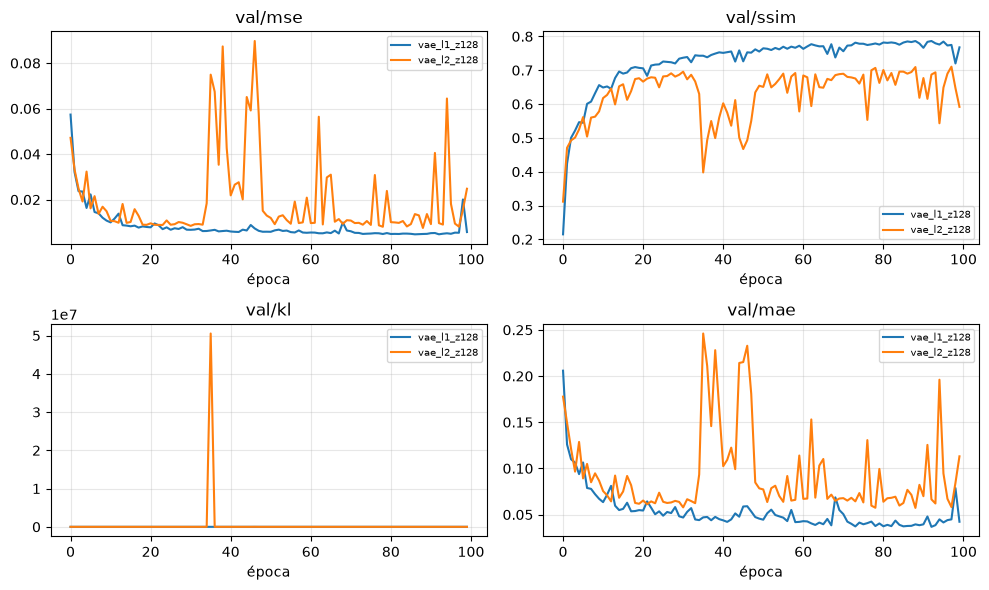

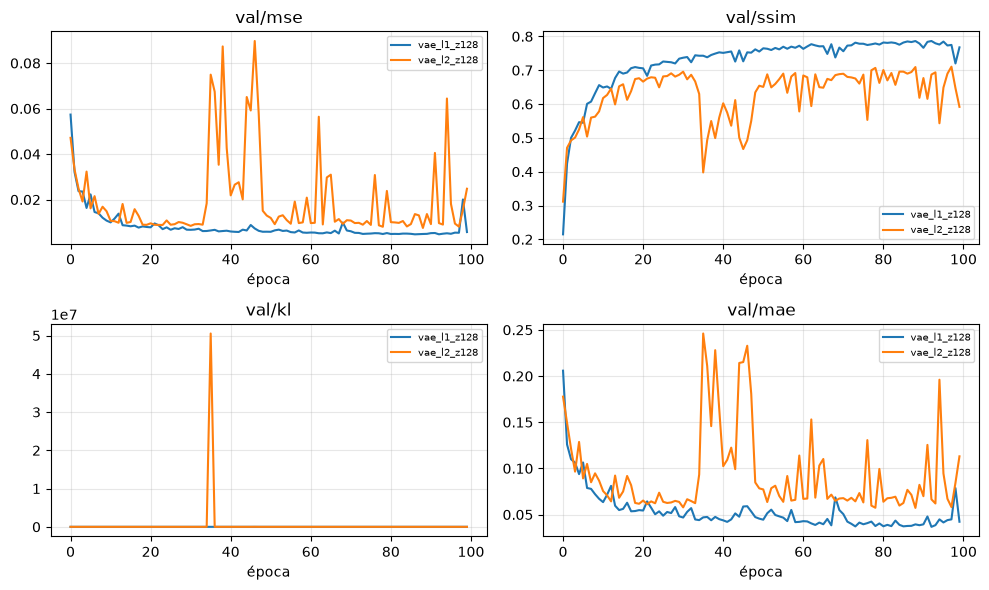

In [ ]:
# [P2]
mejor_vae: str | None = None


def wandb_listo() -> bool:
    """True solo si hay API key y el proceso no forzó un modo sin red."""
    modo = os.environ.get("WANDB_MODE", "")
    if modo in {"disabled", "offline"}:
        return False
    return bool(os.environ.get("WANDB_API_KEY"))


def select_best_vae(tabla: pd.DataFrame) -> str:
    """Elige el run con mayor test/auroc_mean.

    val/loss no entra en el ordenamiento: las cuatro pérdidas no comparten escala.
    El desempate es mayor val/ssim y, después, menor val/mse.
    """
    if "test/auroc_mean" not in tabla.columns or int(tabla["test/auroc_mean"].notna().sum()) == 0:
        raise ValueError("No hay test/auroc_mean para elegir el VAE")
    ordenada = tabla.sort_values(
        by=["test/auroc_mean", "val/ssim", "val/mse"],
        ascending=[False, False, True],
        na_position="last",
    )
    return str(ordenada.iloc[0]["run"])


def plot_vae_curves(historias: dict[str, pd.DataFrame]):
    """Curvas por época leídas de WandB. Devuelve la figura; no la sube."""
    metricas = ["val/mse", "val/ssim", "val/kl", "val/mae"]
    fig, ejes = plt.subplots(2, 2, figsize=(10, 6), squeeze=False)
    for eje, metrica in zip(ejes.flat, metricas):
        for nombre, frame in historias.items():
            columna = metrica if metrica in frame.columns else f"{metrica}_epoch"
            if "epoch" not in frame.columns or columna not in frame.columns:
                continue
            serie = frame.dropna(subset=["epoch", columna])
            eje.plot(serie["epoch"], serie[columna], label=nombre)
        eje.set_title(metrica)
        eje.set_xlabel("época")
        eje.grid(alpha=0.3)
        eje.legend(fontsize=7)
    fig.tight_layout()
    return fig


# Comprobación del criterio. Estas dos filas no son resultados de MVTec.
_ejemplo = pd.DataFrame(
    [
        {"run": "vae_l1_z128", "test/auroc_mean": 0.70, "val/ssim": 0.80, "val/mse": 0.020},
        {"run": "vae_l2_z128", "test/auroc_mean": 0.91, "val/ssim": 0.70, "val/mse": 0.010},
    ]
)
assert select_best_vae(_ejemplo) == "vae_l2_z128"
_figura_ejemplo = plot_vae_curves(
    {
        "vae_l1_z128": pd.DataFrame(
            {"epoch": [0, 1], "val/mse": [0.08, 0.04], "val/ssim": [0.4, 0.6], "val/kl": [2.0, 1.0], "val/mae": [0.2, 0.1]}
        )
    }
)
plt.close(_figura_ejemplo)
print("Criterio y graficador comprobados con series de ejemplo. No son runs de MVTec.")


def _leer_resumen(run) -> dict:
    resumen = run.summary

    def leer(clave: str) -> float | None:
        # Lightning a veces guarda la métrica de época con sufijo _epoch.
        for candidata in (clave, f"{clave}_epoch"):
            valor = resumen.get(candidata)
            if valor is None:
                continue
            try:
                return float(valor)
            except (TypeError, ValueError):
                return None
        return None

    return {
        "run": getattr(run, "name", None) or getattr(run, "id", ""),
        "val/loss": leer("val/loss"),
        "val/mae": leer("val/mae"),
        "val/mse": leer("val/mse"),
        "val/ssim": leer("val/ssim"),
        "val/kl": leer("val/kl"),
        "test/recon_error": leer("test/recon_error"),
        "test/auroc_mean": leer("test/auroc_mean"),
    }


def _historia_run(run) -> pd.DataFrame:
    claves = [
        "epoch",
        "train/loss",
        "val/loss",
        "train/kl",
        "val/kl",
        "train/mse",
        "val/mse",
        "train/mae",
        "val/mae",
        "train/ssim",
        "val/ssim",
        "val/loss_epoch",
        "val/kl_epoch",
        "val/mse_epoch",
        "val/ssim_epoch",
        "val/mae_epoch",
    ]
    filas = []
    for fila in run.scan_history(keys=claves):
        if fila.get("epoch") is None:
            continue
        filas.append(dict(fila))
    return pd.DataFrame(filas)


if not wandb_listo():
    print("Sin WANDB_API_KEY, o con WANDB_MODE disabled/offline: no se consultan los cuatro runs.")
    print("El grupo 'vae' del proyecto tarea03-autoencoder-mvtec es la comparación train/val.")
else:
    try:
        nombres = [str(get_cfg("vae", perdida).logger.name) for perdida in LOSSES]
        resumenes = []
        historias: dict[str, pd.DataFrame] = {}
        for nombre in nombres:
            run = get_wandb_run(nombre)
            resumenes.append(_leer_resumen(run))
            historias[nombre] = _historia_run(run)
        tabla_vae = pd.DataFrame(resumenes)
        display(tabla_vae)
        mejor_vae = select_best_vae(tabla_vae)
        print("Mejor VAE según test/auroc_mean:", mejor_vae)
        figura = plot_vae_curves(historias)
        display(figura)
    except Exception as exc:
        mejor_vae = None
        print("No se pudo leer la comparación desde WandB:", exc)


### [P2] Histogramas de error por subclase

El score es el MSE medio por imagen, el mismo para las cuatro pérdidas (sección 4.5 del acuerdo). Durante `trainer.test`, `TestVisualizationCallback` arma el dataframe con `test_errors_dataframe` y dibuja con `error_histogram_figures`: una figura por clase, buenas en verde y cada subclase de defecto en rojo. Las sube a WandB como `test/hist_error_{clase}`.

Esta celda no vuelve a calcular el error ni redibuja el resultado a mano. Reinserta esas figuras del run elegido (`mejor_vae`) con `show_wandb_images`, que es la vía que el equipo fijó para que las imágenes del notebook salgan de WandB. Sin ese run, llama a `error_histogram_figures` con un marco mínimo para comprobar las columnas y cierra la figura: esa comprobación no es un histograma de MVTec.


Histogramas de vae_ssim_z128


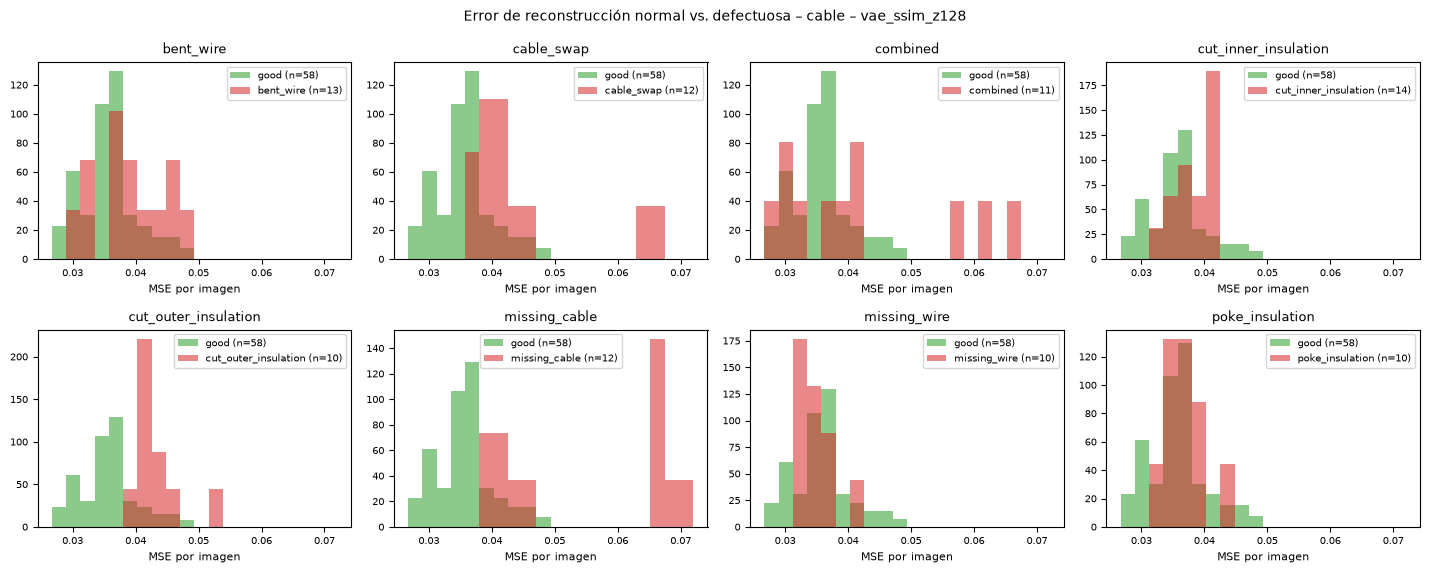

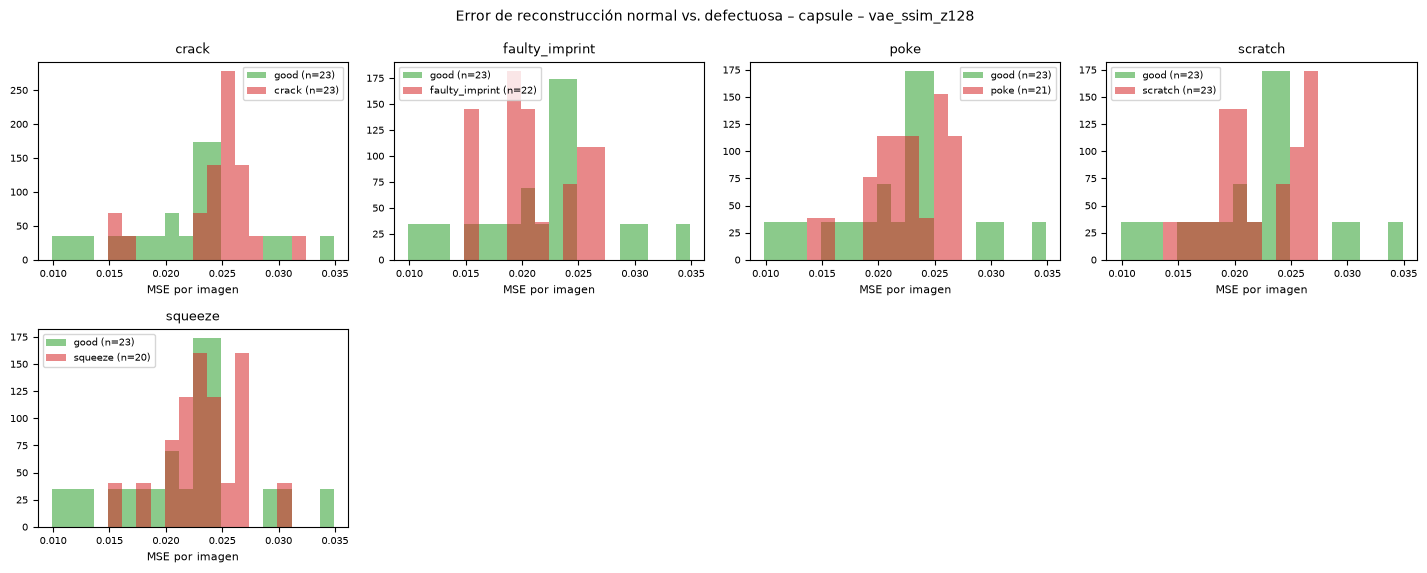

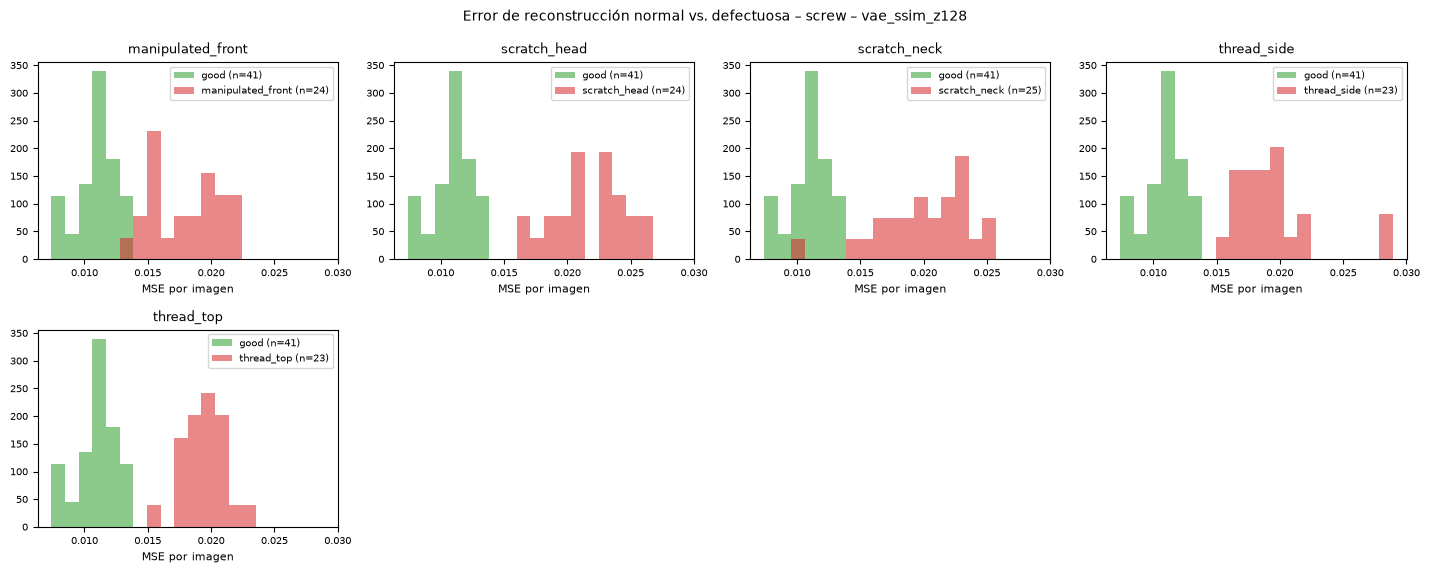

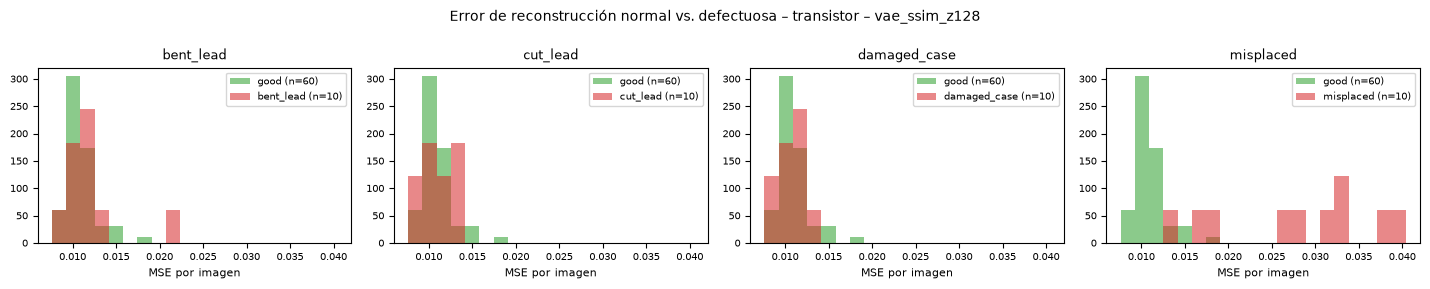

In [ ]:
# [P2]
clases_hist = list(cfg.data.classes)
nombre_mejor = globals().get("mejor_vae")
modo_wandb = os.environ.get("WANDB_MODE", "")
hay_wandb = modo_wandb not in {"disabled", "offline"} and bool(os.environ.get("WANDB_API_KEY"))

if hay_wandb and nombre_mejor:
    print("Histogramas de", nombre_mejor)
    try:
        for clase in clases_hist:
            show_wandb_images(str(nombre_mejor), f"test/hist_error_{clase}")
    except Exception as exc:
        print("No se pudieron reinsertar los histogramas desde WandB:", exc)
else:
    print("Sin run de VAE en WandB: los histogramas reales aparecen al terminar trainer.test.")
    print("Clave: test/hist_error_{clase}, una figura por clase, vía error_histogram_figures de P1.")
    # Decisión: marco sintético de una sola clase para comprobar la firma de la utilidad.
    # Se cierra la figura para no dejarla en el notebook como si fuera un resultado.
    marco = pd.DataFrame(
        {
            "clase": ["cable", "cable", "cable", "cable"],
            "subclase": ["good", "good", "scratch", "scratch"],
            "label": [0, 0, 1, 1],
            "error": [0.010, 0.015, 0.080, 0.090],
        }
    )
    figuras = error_histogram_figures(marco, run_name="comprobacion_p2")
    assert "cable" in figuras
    for figura in figuras.values():
        plt.close(figura)
    print("error_histogram_figures aceptó el esquema clase/subclase/label/error.")


### 14 Análisis crítico del VAE

El módulo es un autoencoder convolucional con un latente gaussiano de dimensión 128. Se entrena solo con imágenes buenas de las cuatro clases juntas. En prueba, una imagen se trata como anómala cuando el MSE de reconstrucción sube. Esa decisión pesa más que el ancho de cada capa.

**Cuello de botella.** No hay skip connections: el decoder solo recibe `z`. Un corte, una grieta o un cable faltante no tiene un atajo espacial para copiarse a la salida. Ese atajo es el riesgo que el acuerdo deja anotado para la U-Net; en el VAE el defecto tiene que sobrevivir dentro de 128 números o perderse. En evaluación se decodifica `mu` y `encode` devuelve `mu`. Las reconstrucciones de los callbacks, el t-SNE y el histograma quedan fijos de una ejecución a otra. Muestrear en evaluación movería el mismo objeto de bin en el histograma y el AUROC dejaría de ser comparable.

**Papel de `beta`.** La pérdida es `recon_loss + beta * KL`, con `KL = -0.5 * mean_B(sum_z(1 + logvar - mu² - exp(logvar)))`. La suma corre sobre las 128 coordenadas y la reconstrucción es una media por píxel, así que `beta = 1` (el número de la plantilla) no es un peso neutro: un posterior apenas distinto de N(0, I) ya suma decenas de nats y domina a L1 o a L2. Se dejó `beta = 1.0e-3` en los cuatro runs. Es una escala, no un óptimo medido en este dataset. En WandB hay dos señales claras. Si `val/kl` cae a cero al poco de empezar, el posterior colapsó, el t-SNE de validación no separa las cuatro clases y el cuello no está representando el objeto: toca subir `beta` o quitar capacidad al decoder. Si `val/kl` crece y `val/mse` de las imágenes buenas se queda alto, el KL está fuerte de más y el histograma se comprime porque todo se reconstruye mal, no solo lo defectuoso. `fc_mu` y `fc_logvar` arrancan en cero para que ese término no explote en el primer paso; a partir de ahí manda `beta`.

**Las cuatro pérdidas comparten cfg y aun así no pesan el KL igual.** `beta` es uno solo, y L2 suele quedar un orden por debajo de `1 - SSIM`. El mismo `beta * KL` es una fracción distinta de cada `recon_loss`. Por eso `val/loss` no sirve para declarar un ganador entre `vae_l1_z128`, `vae_l2_z128`, `vae_ssim_z128` y `vae_ssim_l1_z128`. Las curvas que se superponen son `val/mae`, `val/mse`, `val/ssim` y `val/kl`. De antemano, SSIM+L1 (`alpha = 0.5`) es la candidata más coherente con detección por reconstrucción: L2, y en menor grado L1, favorecen una media borrosa, que es lo mismo que ya empuja el KL. SSIM castiga esa borrosidad. También puede reconstruir demasiado bien un defecto pequeño y bajar el AUROC. Esa tensión se resuelve con `test/auroc_mean`, no con la curva de `val/loss`.

**El score del histograma no es la pérdida de entrenamiento.** AUROC e histogramas usan el MSE medio por imagen aunque el run se haya entrenado con SSIM. Es el acuerdo de la sección 4.5 y permite comparar las cuatro configuraciones. El costo es concreto: un run puede subir `val/ssim` y empeorar el MSE con el que después se separan las anomalías. Hay que leer las dos columnas. Un `val/ssim` alto con `test/auroc_mean` cerca de 0.5 significa que el modelo reconstruye también lo defectuoso, o que falla parecido en todo.

**Cuatro clases, un solo modelo.** El t-SNE de validación (`val/tsne`, coloreado por clase) debería mostrar cuatro grupos si el latente guarda la identidad del objeto. Si los grupos se mezclan, el decoder gasta capacidad en no equivocarse de clase y le queda menos para el detalle fino. 128 dimensiones alcanzan para cuatro objetos de 128×128. Si el t-SNE se ve separado y, aun así, una subclase se solapa con las buenas en `test/hist_error_{clase}`, el defecto es demasiado local para cuatro stride-2: conviene más canales en el mapa 8×8 (`base_channels`) antes que subir `z_dim`. La mayor parte de los parámetros está en `fc_mu`, `fc_logvar` y `fc_dec` (el mapa 256×8×8 aplanado), no en las convoluciones.

**BatchNorm.** En evaluación usa la media móvil estimada con imágenes buenas. Eso es lo que se quiere en test, siempre que el entrenamiento haya corrido las épocas suficientes para estabilizarla. En las primeras épocas los callbacks de validación todavía ven estadísticas a medio aprender; las figuras que importan son las del mejor checkpoint, que es el que usa `trainer.test`.

**Qué queda para cerrar con cifras.** Los cuatro runs de 100 épocas se lanzan con la celda del equipo cuando `RUN_TRAINING = True`, con MVTec ya preparado en `data/mvtec128`. Las figuras tienen que salir de WandB: `val/reconstructions`, `val/tsne`, `test/reconstructions_good_defective`, `test/tsne`, `test/hist_error_{clase}` y el resumen `test/auroc_mean`. Cuando esas claves existan, el cierre de esta sección es citar el run que deje `mejor_vae`, decir si `val/kl` colapsó y señalar qué subclase sigue solapada con las buenas. Hasta entonces `mejor_vae` se deja en blanco a propósito: un ganador inventado no se puede contrastar con el panel del grupo `vae`.


## 11. U-Net (P3)
Plantilla de la firma. `__init__` recibe exactamente las claves de `conf/model/u-net.yaml` + `lr` y `loss_params`.

In [ ]:
class UNetAE(BaseAutoencoder):
    def __init__(self, name, loss, z_dim, lr, in_channels=3, base_channels=32, loss_params=None):
        super().__init__(name=name, loss=loss, z_dim=z_dim, lr=lr, loss_params=loss_params)
        # TODO (P3): encoder con skips, cuello de botella de dimensión z_dim, decoder (sigmoid al final)

    def encode(self, x):
        raise NotImplementedError                 # TODO (P3): z del cuello de botella [B, z_dim]

    def forward(self, x):
        raise NotImplementedError                 # TODO (P3): devuelve (recon, z)

In [ ]:
# Dueño: P3. Los 4 runs de la U-Net (L1, L2, SSIM, SSIM+L1) con los mismos hiperparámetros.
if RUN_TRAINING:
    check_contract(build_model(get_cfg("u-net", "l1")))
    results_unet = run_all("u-net")
    display(results_unet)

NotImplementedError: 

## 12. Comparación de resultados (Todos)
*Pendiente.*

## 13. Conclusiones (Todos)
*Pendiente.*